# Week 5 validation experiment: optional-lead masking

**Question.** How sensitive are the selected multi-scale ResNet and the original unweighted Week 5 ResNet to the three chest leads absent from the dataset's nine-lead recordings? On each **twelve-lead validation record only**, replace standardized V2, V4, and V6 with zero, preserving all other channels and the original first-10-second preprocessing. Compare each frozen checkpoint's predictions before and after this intervention on identical records. No training, checkpoint selection, threshold optimization, or test-set access occurs.

The positive target is an exact match to any of 19 selected ICD-10 codes in the metadata field, not an ECG diagnostic statement. A negative record merely lacks those selected codes. This is a perturbation and robustness probe: zeroing real leads removes information and creates a distribution shift, so changes cannot uniquely identify shortcut learning or a clinical mechanism. The 0.5 threshold is fixed from the prior comparison. Outputs are confined to this folder.

In [1]:
from pathlib import Path
import csv, importlib.util, json, os, random, sys
import numpy as np, pandas as pd, torch, wfdb
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Data/AttributesDictionary.csv').is_file())
OUT=ROOT/'new work/Week5/experimental/lead_availability_probe'
RECORDS=ROOT/'Child_ECG/Child_ecg'; FS=500; N_SAMPLES=5000; SEED=42
assert Path(sys.executable).resolve()==(ROOT/'venv/bin/python').resolve()
assert torch.cuda.is_available(), 'This GPU experiment requires CUDA in the notebook kernel.'
DEVICE=torch.device('cuda'); torch.set_num_threads(min(4,os.cpu_count() or 1))
torch.manual_seed(SEED); np.random.seed(SEED)
print('Python',sys.executable,'PyTorch',torch.__version__,'CUDA',torch.cuda.get_device_name(0))

Python /home/souhit/Documents/Research/Pediatric_ECG/venv/bin/python PyTorch 2.6.0+cu124 CUDA NVIDIA GeForce RTX 3060 Laptop GPU


## Reconstruct validation records and verify the label

Use the existing validation prediction table to identify validation patients and order. The metadata pass reads the patient ID first and skips every non-validation row before inspecting its label or file path. This does not touch test waveforms or labels.

In [2]:
preds=pd.read_csv(ROOT/'new work/Week5/experimental/validation_predictions.csv')
val_ids=set(preds.patient_id.astype(str))
selected_codes=set(pd.read_csv(ROOT/'Data/DiseaseCode.csv').query('`Disease Type` != "Other diseases(OD)"')['ICD-10 Code'].astype(str).str.strip())
assert len(selected_codes)==19
def tokens(s): return [v.strip().strip("'\"").strip() for v in s.split(';') if v.strip()]
rows=[]
with (ROOT/'Data/AttributesDictionary.csv').open(newline='') as f:
    for row in csv.DictReader(f):
        if row['Patient_ID'] not in val_ids: continue
        rows.append({'patient_id':row['Patient_ID'],'Filename':row['Filename'],'Sampling_point':int(row['Sampling_point']),
                     'Lead':int(row['Lead']),'target':int(bool(set(tokens(row['ICD-10 code']))&selected_codes))})
val=pd.DataFrame(rows)
assert len(val)==len(preds)==2169
assert (val.patient_id.to_numpy()==preds.patient_id.astype(str).to_numpy()).all()
assert (val.target.to_numpy()==preds.target.to_numpy()).all()
subset=val[val.Lead==12].copy(); subset['validation_index']=subset.index
assert len(subset)==1888 and subset.target.sum()==426
print('12-lead validation records',len(subset),'positives',int(subset.target.sum()),'prevalence',subset.target.mean())

12-lead validation records 1888 positives 426 prevalence 0.225635593220339


In [3]:
LEADS=['I','II','III','AVR','AVL','AVF','V1','V2','V3','V4','V5','V6']; lead_index={v:i for i,v in enumerate(LEADS)}
MASKED_LEADS=['V2','V4','V6']; masked_indices=[lead_index[v] for v in MASKED_LEADS]
class ECGValidation(Dataset):
    def __init__(self,frame): self.frame=frame.reset_index(drop=True)
    def __len__(self): return len(self.frame)
    def __getitem__(self,i):
        r=self.frame.iloc[i]
        sig,fields=wfdb.rdsamp(str(RECORDS/r.Filename),sampto=min(N_SAMPLES,int(r.Sampling_point)))
        assert fields['fs']==FS and np.isfinite(sig).all() and len(fields['sig_name'])==12
        x=np.zeros((12,N_SAMPLES),dtype=np.float32)
        for j,lead in enumerate(fields['sig_name']):
            k=lead_index[lead.upper()]; v=sig[:,j].astype(np.float32); sd=v.std()
            x[k,:len(v)]=(v-v.mean())/sd if sd>1e-8 else 0
        return torch.from_numpy(x),int(r.target)
loader=DataLoader(ECGValidation(subset),batch_size=16,shuffle=False,num_workers=2)
def import_class(name,path,class_name):
    spec=importlib.util.spec_from_file_location(name,path); module=importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module); return getattr(module,class_name)
ResNet1D=import_class('week5_models',ROOT/'NoteBooks/Week5/models.py','ResNet1D')
MultiScaleResNet1D=import_class('week8_models',ROOT/'NoteBooks/Week8/ExperimentB/models.py','MultiScaleResNet1D')
model_specs={'week5_resnet_unweighted':(ResNet1D,ROOT/'NoteBooks/Week5/disease_labelled/resnet_unweighted_best.pth'),
             'multiscale_resnet':(MultiScaleResNet1D,ROOT/'new work/Week5/experimental/multiscale_resnet_best.pth')}
def load_model(cls,path):
    ckpt=torch.load(path,map_location=DEVICE,weights_only=False)
    assert ckpt['lead_order']==LEADS and ckpt['input_samples']==N_SAMPLES
    net=cls(2).to(DEVICE);net.load_state_dict(ckpt['model_state_dict']);net.eval()
    return net
models={name:load_model(*spec) for name,spec in model_specs.items()}
print('Frozen checkpoints loaded:',list(models))

Frozen checkpoints loaded: ['week5_resnet_unweighted', 'multiscale_resnet']


In [4]:
original={name:[] for name in models};masked={name:[] for name in models}; ys=[]
with torch.inference_mode():
    for batch,(x,y) in enumerate(loader):
        x=x.to(DEVICE);xm=x.clone();xm[:,masked_indices,:]=0
        ys.extend(y.tolist())
        for name,model in models.items():
            original[name].extend(torch.softmax(model(x),dim=1)[:,1].cpu().numpy().tolist())
            masked[name].extend(torch.softmax(model(xm),dim=1)[:,1].cpu().numpy().tolist())
        if (batch+1)%25==0:print('processed',min((batch+1)*16,len(subset)),'/',len(subset),flush=True)
assert np.array_equal(np.asarray(ys),subset.target.to_numpy())
for name in models:
    saved=preds.loc[subset.validation_index,name+'_probability'].to_numpy()
    error=np.max(np.abs(np.asarray(original[name])-saved))
    print(name,'max absolute difference from prior original predictions',error)
    assert error<1e-4, 'Original inference does not reproduce the saved validation predictions.'
results=pd.DataFrame({'validation_index':subset.validation_index.to_numpy(),
                      'patient_id':subset.patient_id.to_numpy(),'target':subset.target.to_numpy(),
                      'age_years':preds.loc[subset.validation_index,'age_years'].to_numpy(),
                      'lead_count':subset.Lead.to_numpy()})
for name in models:
    results[name+'_original']=original[name];results[name+'_masked']=masked[name]
    results[name+'_delta']=np.asarray(masked[name])-np.asarray(original[name])
results.to_csv(OUT/'paired_predictions.csv',index=False)
print('Saved',OUT/'paired_predictions.csv')

processed 400 / 1888


processed 800 / 1888


processed 1200 / 1888


processed 1600 / 1888


week5_resnet_unweighted max absolute difference from prior original predictions 1.1920928955078125e-07
multiscale_resnet max absolute difference from prior original predictions 4.4167041778619964e-05
Saved /home/souhit/Documents/Research/Pediatric_ECG/new work/Week5/experimental/lead_availability_probe/paired_predictions.csv


## Paired validation metrics

All values below refer to the same 1,888 twelve-lead validation records. The original predictions are checked against the prior comparison. The perturbed inputs are outside the model's training distribution. Confidence intervals from patient resampling below describe variation within this selected validation set; they are not independent generalization evidence.

In [5]:
def score(y,p):
    y=np.asarray(y,dtype=int);p=np.asarray(p);yp=(p>=.5).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,yp,labels=[0,1]).ravel()
    return {'n':len(y),'positive_n':int(y.sum()),'prevalence':y.mean(),
            'accuracy':accuracy_score(y,yp),'sensitivity':tp/(tp+fn) if tp+fn else np.nan,
            'specificity':tn/(tn+fp) if tn+fp else np.nan,
            'precision':precision_score(y,yp,zero_division=0),'f1':f1_score(y,yp,zero_division=0),
            'auroc':roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan,
            'average_precision':average_precision_score(y,p) if y.sum() else np.nan,
            'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)}
rows=[]
for name in models:
    for condition in ['original','masked']:
        m=score(results.target,results[name+'_'+condition]);rows.append({'model':name,'condition':condition,**m})
metric_table=pd.DataFrame(rows)
metric_table.to_csv(OUT/'metrics.csv',index=False)
display(metric_table.round(4))
switches=[]
for name in models:
    orig=(results[name+'_original']>=.5).to_numpy();mask=(results[name+'_masked']>=.5).to_numpy()
    switches.append({'model':name,'positive_to_negative':int((orig&~mask).sum()),
                     'negative_to_positive':int((~orig&mask).sum()),
                     'median_probability_change':float(results[name+'_delta'].median()),
                     'mean_absolute_probability_change':float(results[name+'_delta'].abs().mean())})
switch_table=pd.DataFrame(switches);switch_table.to_csv(OUT/'switches.csv',index=False)
display(switch_table.round(4))

,model,condition,n,positive_n,prevalence,accuracy,sensitivity,specificity,precision,f1,auroc,average_precision,tn,fp,fn,tp
0,week5_resnet_unweighted,original,1888,426,0.2256,0.8268,0.3427,0.9679,0.7565,0.4717,0.7869,0.6076,1415,47,280,146
1,week5_resnet_unweighted,masked,1888,426,0.2256,0.7082,0.5610,0.7510,0.3964,0.4645,0.7208,0.5137,1098,364,187,239
2,multiscale_resnet,original,1888,426,0.2256,0.8279,0.3944,0.9542,0.7149,0.5083,0.7946,0.6237,1395,67,258,168
3,multiscale_resnet,masked,1888,426,0.2256,0.7458,0.5822,0.7934,0.4509,0.5082,0.7473,0.5345,1160,302,178,248


,model,positive_to_negative,negative_to_positive,median_probability_change,mean_absolute_probability_change
0,week5_resnet_unweighted,3,413,0.2062,0.2204
1,multiscale_resnet,5,320,0.1720,0.1973


In [6]:
age=results.age_years.to_numpy()
strata={'age <2y':age<2,'age 2–<6y':(age>=2)&(age<6),
        'age 6–<12y':(age>=6)&(age<12),'age >=12y':age>=12}
subrows=[]
for name in models:
    for condition in ['original','masked']:
        for label,mask in strata.items():
            subrows.append({'model':name,'condition':condition,'age_group':label,
                            **score(results.target.to_numpy()[mask],results[name+'_'+condition].to_numpy()[mask])})
subgroup=pd.DataFrame(subrows);subgroup.to_csv(OUT/'age_subgroups.csv',index=False)
display(subgroup[['model','condition','age_group','n','positive_n','prevalence','sensitivity','specificity','auroc','average_precision']].round(4))
# Patient-clustered paired resampling, descriptive only.
rng=np.random.default_rng(SEED); patient=results.patient_id.to_numpy(); keys=np.unique(patient)
index_by_patient={k:np.flatnonzero(patient==k) for k in keys}
boot=[]
for rep in range(300):
    ix=np.concatenate([index_by_patient[k] for k in rng.choice(keys,size=len(keys),replace=True)])
    y=results.target.to_numpy()[ix]
    if len(np.unique(y))<2:continue
    for name in models:
        a=score(y,results[name+'_original'].to_numpy()[ix]);b=score(y,results[name+'_masked'].to_numpy()[ix])
        boot.append({'replicate':rep,'model':name,**{k+'_delta':b[k]-a[k] for k in ['sensitivity','specificity','auroc','average_precision','f1']}})
boot=pd.DataFrame(boot)
intervals=boot.groupby('model').agg({c:['mean',lambda s:s.quantile(.025),lambda s:s.quantile(.975)] for c in boot.columns if c.endswith('_delta')})
intervals.columns=[f'{metric}_{stat if isinstance(stat,str) else ("q025" if i%3==1 else "q975")}' for i,(metric,stat) in enumerate(intervals.columns)]
intervals.to_csv(OUT/'paired_patient_bootstrap.csv')
display(intervals.round(4))

,model,condition,age_group,n,positive_n,prevalence,sensitivity,specificity,auroc,average_precision
0,week5_resnet_unweighted,original,age <2y,89,44,0.4944,0.6136,0.9556,0.9121,0.9222
1,week5_resnet_unweighted,original,age 2–<6y,405,159,0.3926,0.3899,0.9593,0.7863,0.7434
2,week5_resnet_unweighted,original,age 6–<12y,794,133,0.1675,0.3308,0.9743,0.8173,0.5709
3,week5_resnet_unweighted,original,age >=12y,600,90,0.1500,0.1444,0.9647,0.6353,0.2734
4,week5_resnet_unweighted,masked,age <2y,89,44,0.4944,0.8182,0.8000,0.8919,0.9099
5,week5_resnet_unweighted,masked,age 2–<6y,405,159,0.3926,0.5975,0.7683,0.7560,0.7249
6,week5_resnet_unweighted,masked,age 6–<12y,794,133,0.1675,0.5639,0.7670,0.7376,0.4336
7,week5_resnet_unweighted,masked,age >=12y,600,90,0.1500,0.3667,0.7176,0.5861,0.2378
8,multiscale_resnet,original,age <2y,89,44,0.4944,0.7727,0.7778,0.8525,0.8734
9,multiscale_resnet,original,age 2–<6y,405,159,0.3926,0.4340,0.9390,0.7899,0.7512


,sensitivity_delta_mean,sensitivity_delta_<lambda_0>,sensitivity_delta_<lambda_1>,specificity_delta_mean,specificity_delta_<lambda_0>,specificity_delta_<lambda_1>,auroc_delta_mean,auroc_delta_<lambda_0>,auroc_delta_<lambda_1>,average_precision_delta_mean,average_precision_delta_<lambda_0>,average_precision_delta_<lambda_1>,f1_delta_mean,f1_delta_<lambda_0>,f1_delta_<lambda_1>
model,,,,,,,,,,,,,,,
multiscale_resnet,0.1904,0.1521,0.2326,-0.1593,-0.1808,-0.1407,-0.0466,-0.0662,-0.0277,-0.0870,-0.1184,-0.0575,0.0036,-0.0393,0.0470
week5_resnet_unweighted,0.2199,0.1768,0.2685,-0.2176,-0.2417,-0.1955,-0.0649,-0.0934,-0.0380,-0.0915,-0.1232,-0.0536,-0.0066,-0.0547,0.0417


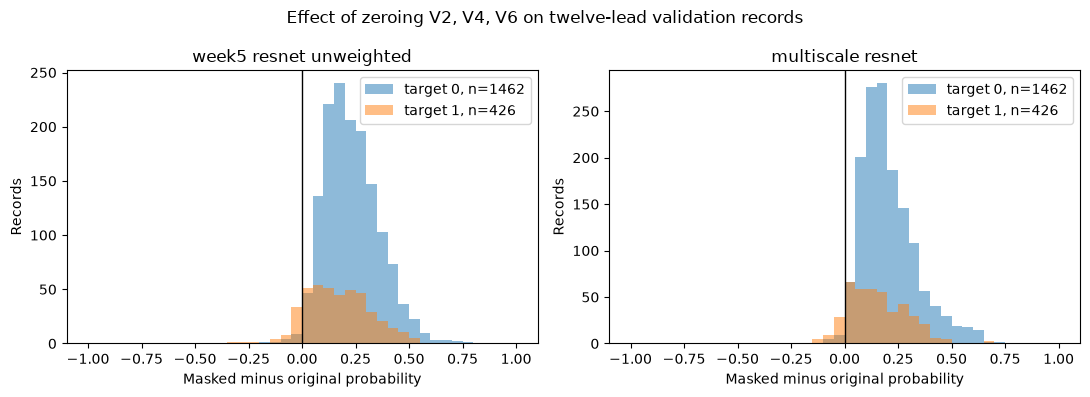

In [7]:
import matplotlib.pyplot as plt
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,(name,_) in zip(axs,models.items()):
    for label,color in [(0,'tab:blue'),(1,'tab:orange')]:
        v=results.loc[results.target==label,name+'_delta'].to_numpy()
        ax.hist(v,bins=np.linspace(-1,1,41),alpha=.5,color=color,label=f'target {label}, n={len(v)}')
    ax.axvline(0,color='black',linewidth=1);ax.set(title=name.replace('_',' '),xlabel='Masked minus original probability',ylabel='Records')
    ax.legend()
fig.suptitle('Effect of zeroing V2, V4, V6 on twelve-lead validation records')
fig.tight_layout();fig.savefig(OUT/'probability_shifts.png',dpi=160)
plt.show()

## Interpretation and limits

**Observed on the same 1,888 twelve-lead validation records** (426 selected-code positive; prevalence 22.56%; 1555 patients):

| Frozen model | Condition | Sensitivity | Specificity | AUROC | AP | F1 | TN / FP / FN / TP |
|---|---|---:|---:|---:|---:|---:|---:|
| Week 5 unweighted ResNet | Original | 0.3427 | 0.9679 | 0.7869 | 0.6076 | 0.4717 | 1415 / 47 / 280 / 146 |
| Week 5 unweighted ResNet | V2/V4/V6 zeroed | 0.5610 | 0.7510 | 0.7208 | 0.5137 | 0.4645 | 1098 / 364 / 187 / 239 |
| Multi-scale ResNet | Original | 0.3944 | 0.9542 | 0.7946 | 0.6237 | 0.5083 | 1395 / 67 / 258 / 168 |
| Multi-scale ResNet | V2/V4/V6 zeroed | 0.5822 | 0.7934 | 0.7473 | 0.5345 | 0.5082 | 1160 / 302 / 178 / 248 |

Masking shifted 410 Week 5 ResNet and 315 multi-scale ResNet records across the fixed 0.5 decision boundary toward a positive prediction, net of a few reverse switches. AP and AUROC fell for both models. The multi-scale model's AP decreased by 0.0892, AUROC by 0.0473, and specificity by 0.1607; its sensitivity increased by 0.1878. The Week 5 ResNet's AP decreased by 0.0939, AUROC by 0.0660, and specificity by 0.2168; its sensitivity increased by 0.2183. Patient-clustered descriptive resampling intervals for the multi-scale AP and AUROC changes were −0.1184 to −0.0575 and −0.0662 to −0.0277. These intervals describe the selected validation patients only.

**Interpretation.** Both frozen classifiers are materially sensitive to removing these leads. Their higher sensitivity is paired with many more false positives and worse discrimination, so it is not an improvement. The multi-scale model shows a smaller specificity and AUROC loss in this perturbation, but this is not evidence of superior performance on naturally acquired nine-lead ECGs or on unseen patients.

**What this cannot establish.** Replacing real chest leads with zeros removes genuine waveform information and changes the input distribution. The observed shift cannot separate a lead-presence shortcut from loss of useful ECG morphology. No retraining, threshold tuning, test-set inference, or clinical interpretation was performed. A matched V1/V3/V5 masking control is reported in `Matched_Lead_Control.ipynb`; independent validation would be needed before a generalization claim. The target remains metadata matching of 19 selected ICD-10 codes; a negative label is not an adjudicated absence of cardiovascular disease.